# Start

In [1]:
from pyprojroot import here
import polars as pl
import cv2
import numpy as np
from typing import Literal
import matplotlib.pyplot as plt
import seaborn as sns
import os
from skimage.filters import frangi

In [2]:
# params
path_data = here() / "data"
path_processed = path_data / "processed"
path_raw = path_data / "raw"
path_raw_img = path_raw / "Images"
path_sample_img = path_raw_img / "31_2.jpg"
path_crop_out = path_processed / "od_images"

size_preview = (500, 500)

seed = 123

In [3]:
df = pl.read_csv(path_processed / "labels.csv")
df.head()

Image Name,Patient,Label,Quality Score,SPLIT,Height,Width
str,i64,str,f64,str,i64,i64
"""0_0.jpg""",0,"""GON+""",6.18,"""TRAIN""",1918,1918
"""1_0.jpg""",1,"""GON+""",5.31,"""TRAIN""",1929,1929
"""1_1.jpg""",1,"""GON+""",4.37,"""TRAIN""",1940,1940
"""2_0.jpg""",2,"""GON+""",3.51,"""TRAIN""",1893,1893
"""2_1.jpg""",2,"""GON+""",4.24,"""TRAIN""",1900,1900


# Tools

In [4]:
def imshow(input) -> None:
    if type(input) is not np.ndarray:
        _img = cv2.imread(input)
    else:
        _img = input
    _img_resize = cv2.resize(_img, size_preview)
    cv2.imshow("Preview window", _img_resize)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [5]:
def imshow_c(input, channel: Literal["B", "G", "R"]) -> None:
    if type(input) is not np.ndarray:
        _img = cv2.imread(input)
    else:
        _img = input
    _img_resize = cv2.resize(_img, size_preview)
    _img_channel = _img_resize[:, :, {"B": 0, "G": 1, "R": 2}[channel]]
    cv2.imshow("Preview window", _img_channel)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [6]:
def imshow_2(in1:np.ndarray, in2:np.ndarray) -> None:
    _in1_resize = cv2.resize(in1, size_preview)
    _in2_resize = cv2.resize(in2, size_preview)
    _concat = np.concatenate([_in1_resize, _in2_resize], axis=1)
    cv2.imshow("Preview window", _concat)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [7]:
def imshow_3(in1:np.ndarray, in2:np.ndarray, in3:np.ndarray) -> None:
    _in1_resize = cv2.resize(in1, size_preview)
    _in2_resize = cv2.resize(in2, size_preview)
    _in3_resize = cv2.resize(in3, size_preview)
    _concat = np.concatenate([_in1_resize, _in2_resize, _in3_resize], axis=1)
    cv2.imshow("Preview window", _concat)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [8]:
def mark(img, max_loc, crop_ratio=0.3):
    out = img.copy()
    h, w = out.shape[:2]

    crop_w = int(w * crop_ratio)
    crop_h = int(h * crop_ratio)

    x1 = max(max_loc[0] - crop_w // 2, 0)
    y1 = max(max_loc[1] - crop_h // 2, 0)
    x2 = min(max_loc[0] + crop_w // 2, w)
    y2 = min(max_loc[1] + crop_h // 2, h)

    cv2.rectangle(out, (x1, y1), (x2, y2), (0, 255, 0), 10)
    cv2.drawMarker(out, max_loc, (0, 0, 255), cv2.MARKER_CROSS, 100, 15)

    return out

In [9]:
def shade_fov_region(img, mask, alpha=0.4, color=(0, 255, 0)):
    """
    Shades the 'ignored' regions of an image based on a binary mask.

    Args:
        img: Original BGR image.
        mask: Binary mask (uint8, same size as img). 255 = keep, 0 = shade.
        alpha: Transparency of the shade (0.0 to 1.0).
        color: BGR color for the shade
    """
    overlay = img.copy()

    if len(mask.shape) == 3:
        mask = cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY)
    overlay[mask == 0] = color
    output = cv2.addWeighted(overlay, alpha, img, 1 - alpha, 0)

    return output

In [10]:
def crop_od(img, max_loc, crop_ratio=0.3):
    img_ori = img.copy()

    crop_resize = 512
    sample_height = img_ori.shape[0]
    sample_width = img_ori.shape[1]

    # cropping
    crop_width = int(sample_width * crop_ratio)
    crop_height = int(sample_height * crop_ratio)

    x1 = max(max_loc[0] - crop_width // 2, 0)
    y1 = max(max_loc[1] - crop_height // 2, 0)
    x2 = min(max_loc[0] + crop_width // 2, sample_width)
    y2 = min(max_loc[1] + crop_height // 2, sample_height)

    cropped_img = img_ori[y1:y2, x1:x2]
    cropped_resize_img = cv2.resize(cropped_img, (crop_resize, crop_resize))

    return cropped_resize_img

# OD - ensemble

In [11]:
# Params
crop_ratio = 0.3
crop_resize = 512

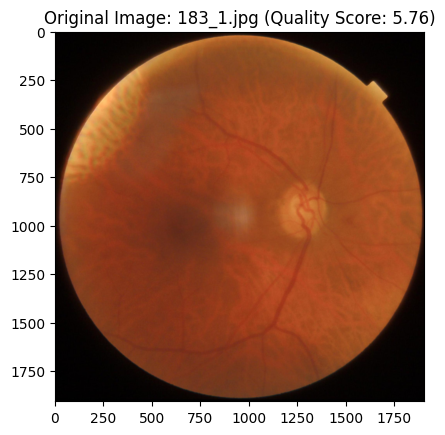

In [12]:
# img_file_name = "273_0"  # od near fov
# img_file_name = "261_1"  # od near fov + generally bright
# img_file_name = "188_1"  # od near fov
# img_file_name = "31_2"  # random white spot + halo
# img_file_name = "217_0" # 2 bright spot
img_file_name = None

# generate random sample + extract metadata
sample_df = (
    df.filter(pl.col("SPLIT") == "TRAIN").sample(1)
    if img_file_name is None
    else df.filter(pl.col("Image Name") == img_file_name + ".jpg")
)
sample_img_name = sample_df.select("Image Name").item()
sample_quality = sample_df.select("Quality Score").item()
sample_path = path_raw_img / sample_img_name
sample_height = sample_df.select("Height").item()
sample_width = sample_df.select("Width").item()

# load and preview
img_ori = cv2.imread(sample_path)
plt.title(f"Original Image: {sample_img_name} (Quality Score: {sample_quality})")
plt.imshow(cv2.cvtColor(img_ori, cv2.COLOR_BGR2RGB))

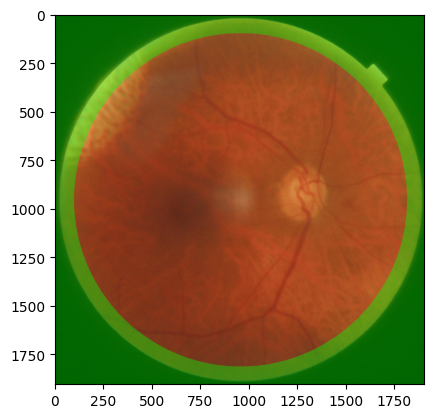

In [13]:
# get fov mask
def get_fov_mask(img_input):
    gray = img_input[:, :, 1]  # Green channel (cleanest boundary)
    blurred = cv2.medianBlur(gray, 31)
    circles = cv2.HoughCircles(
        blurred,
        cv2.HOUGH_GRADIENT,
        dp=1.2,
        minDist=1000,  # Assume only ONE big circle exists
        param1=50,
        param2=30,
        minRadius=int(img_input.shape[0] * 0.3),  # At least 30% of image height
        maxRadius=int(img_input.shape[0] * 0.6),
    )
    mask = np.zeros_like(gray)
    if circles is not None:
        circles = np.uint16(np.around(circles))
        for i in circles[0, :]:
            center = (i[0], i[1])  # x, y
            radius = i[2]
            # Draw the detected circle into a binary mask
            mask = cv2.circle(mask, center, radius, 255, -1)

    # erode fov mask
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (51, 51))
    mask_eroded = cv2.erode(mask, kernel, iterations=3)

    return mask_eroded


plt.imshow(
    cv2.cvtColor(shade_fov_region(img_ori, get_fov_mask(img_ori)), cv2.COLOR_BGR2RGB)
)

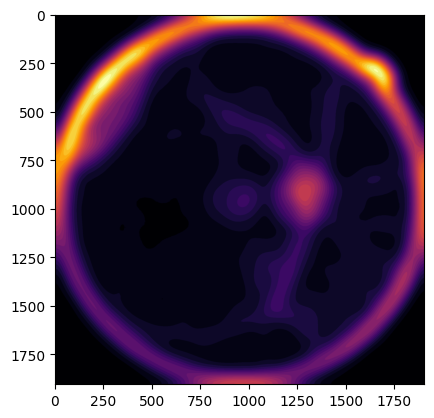

In [14]:
def get_texture_map(img_bgr):
    red = img_bgr[:, :, 1]
    red = cv2.medianBlur(red, 15)  # Remove speckle noise

    # Structural Gradient (Dilation - Erosion)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    grad = cv2.morphologyEx(red, cv2.MORPH_GRADIENT, kernel)

    # Create a "Hotspot" of density
    blur_size = int(img_bgr.shape[1] * 0.15)  # 15% of width
    if blur_size % 2 == 0:
        blur_size += 1
    texture_density = cv2.GaussianBlur(grad, (blur_size, blur_size), 0)

    return cv2.normalize(texture_density, None, 0, 1, cv2.NORM_MINMAX, dtype=cv2.CV_32F)


texture_map = get_texture_map(img_ori)
plt.imshow(texture_map, cmap="inferno")

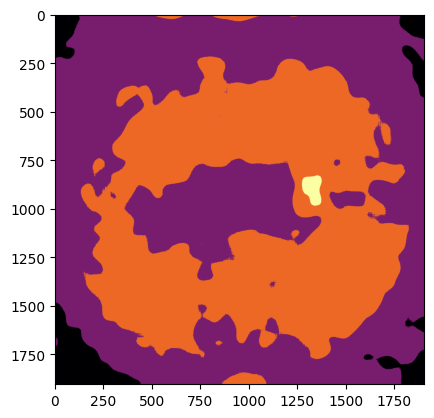

In [15]:
def get_vessel_map(img):
    green = img[:, :, 1]
    vessels = cv2.morphologyEx(
        green,
        cv2.MORPH_BLACKHAT,
        cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)),
    )
    vessel_density = cv2.GaussianBlur(vessels, (201, 201), 0)
    vessel_map = cv2.normalize(
        vessel_density, None, 0, 1, cv2.NORM_MINMAX, dtype=cv2.CV_32F
    )
    return vessel_map


vessel_map = get_vessel_map(img_ori)
plt.imshow(vessel_map, cmap="inferno")

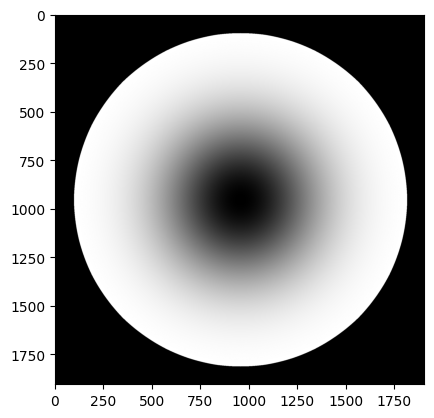

In [16]:
def get_spatial_prior(fov_mask):
    h, w = fov_mask.shape
    M = cv2.moments(fov_mask)
    if M["m00"] != 0:
        cX = int(M["m10"] / M["m00"])
        cY = int(M["m01"] / M["m00"])
    else:
        cX, cY = w // 2, h // 2

    x = np.linspace(0, w, w)
    y = np.linspace(0, h, h)
    X, Y = np.meshgrid(x, y)
    sigma = w * 0.15
    central_valley = 1 - np.exp(-((X - cX) ** 2 + (Y - cY) ** 2) / (2 * sigma**2))
    prior = central_valley * (fov_mask.astype(np.float32) / 255.0)

    return cv2.normalize(prior, None, 0, 1, cv2.NORM_MINMAX)


fov_mask = get_fov_mask(img_ori)
spatial_prior = get_spatial_prior(fov_mask)
plt.imshow(spatial_prior, cmap="grey")

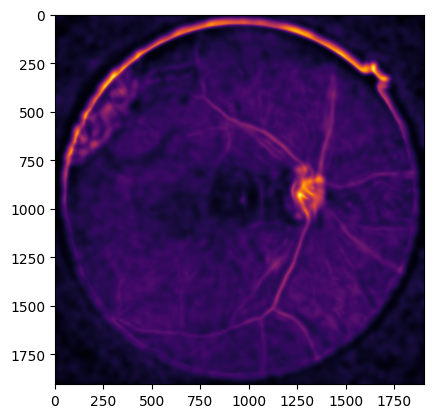

In [17]:
# avoid random white spot on top branched vessel which similar to OD
def get_symmetry_map(img_bgr):
    green = img_bgr[:, :, 1]
    green = cv2.GaussianBlur(green, (7, 7), 0)

    gx = cv2.Sobel(green, cv2.CV_32F, 1, 0, ksize=5)
    gy = cv2.Sobel(green, cv2.CV_32F, 0, 1, ksize=5)
    mag, ang = cv2.cartToPolar(gx, gy)

    # Accumulate radial symmetry (simplified for performance)
    cos_map = cv2.GaussianBlur(np.cos(ang) * mag, (101, 101), 0)
    sin_map = cv2.GaussianBlur(np.sin(ang) * mag, (101, 101), 0)
    hub_evidence = cv2.GaussianBlur(mag, (101, 101), 0) - cv2.magnitude(
        cos_map, sin_map
    )

    return cv2.normalize(hub_evidence, None, 0, 1, cv2.NORM_MINMAX)


symmetry_map = get_symmetry_map(img_ori)
plt.imshow(symmetry_map, cmap="inferno")

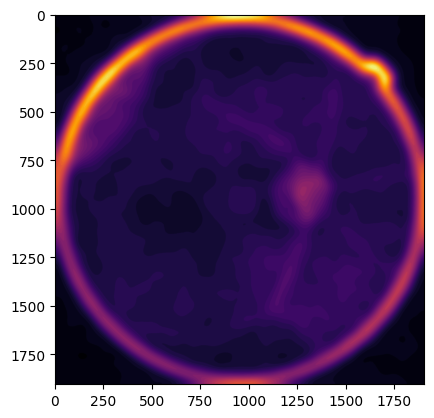

In [18]:
def get_symmetry_map2(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    grad = cv2.morphologyEx(gray, cv2.MORPH_GRADIENT, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)))
    texture_expert = cv2.GaussianBlur(grad, (201, 201), 0)
    texture_expert = cv2.normalize(texture_expert.astype(np.float32), None, 0, 1, cv2.NORM_MINMAX)
    return texture_expert

symmetry_map2 = get_symmetry_map2(img_ori)
plt.imshow(symmetry_map2, cmap="inferno")

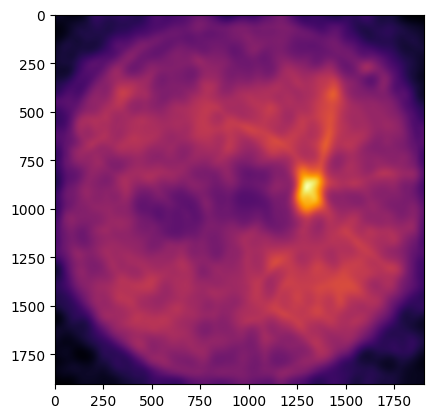

In [19]:
def get_vessel_map2(img):
    green = img[:, :, 1]
    # Highlight vessels using Black-Hat
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21))
    vessels = cv2.morphologyEx(green, cv2.MORPH_BLACKHAT, kernel)

    # Calculate symmetry (Directional clash)
    gx = cv2.Sobel(vessels, cv2.CV_32F, 1, 0, ksize=5)
    gy = cv2.Sobel(vessels, cv2.CV_32F, 0, 1, ksize=5)
    mag, ang = cv2.cartToPolar(gx, gy)

    # Vectors cancel out at the hub
    cos_blur = cv2.GaussianBlur(np.cos(ang) * mag, (201, 201), 0)
    sin_blur = cv2.GaussianBlur(np.sin(ang) * mag, (201, 201), 0)
    mag_blur = cv2.GaussianBlur(mag, (201, 201), 0)
    vessel_expert = cv2.normalize(
        mag_blur - cv2.magnitude(cos_blur, sin_blur), None, 0, 1, cv2.NORM_MINMAX
    )
    return vessel_expert

vessel_map2 = get_vessel_map2(img_ori)
plt.imshow(vessel_map2, cmap="inferno")

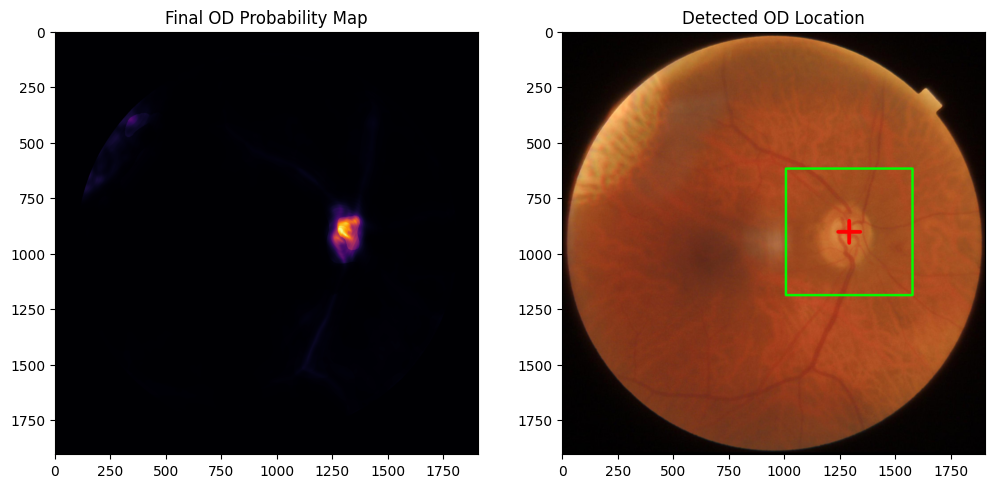

In [20]:
def find_od(map_ls: list):
    # FIND OVERLAPPING MAP
    combined_prob = None
    for map in map_ls:
        if combined_prob is None:
            combined_prob = map
        else:
            combined_prob *= map

    final_map = combined_prob

    # LOCATE THE PEAK
    final_map_8u = cv2.normalize(final_map, None, 0, 255, cv2.NORM_MINMAX).astype(
        np.uint8
    )
    _, _, _, max_loc = cv2.minMaxLoc(final_map_8u)

    return max_loc, final_map_8u


fov_mask = get_fov_mask(img_ori)
max_loc, final_map = find_od(
    map_ls=[
        texture_map,
        vessel_map,
        vessel_map2,
        symmetry_map,
        symmetry_map2,
        spatial_prior,
    ],
)

# Visualize the final OD probability map and the detected location
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Final OD Probability Map")
plt.imshow(final_map, cmap="inferno")
plt.subplot(1, 2, 2)
img_marked = mark(img_ori, max_loc)
plt.title("Detected OD Location")
plt.imshow(cv2.cvtColor(img_marked, cv2.COLOR_BGR2RGB))

# OD Batch crop

In [21]:
class OD:
    def __init__(self, img):
        self.img = img
        self.fov_mask = self.get_fov_mask(img)
        self.texture_map = self.get_texture_map(img)
        self.vessel_map = self.get_vessel_map(img)
        self.spatial_prior = self.get_spatial_prior(self.fov_mask)
        self.symmetry_map = self.get_symmetry_map(img)
        self.symmetry_map2 = self.get_symmetry_map2(img)
        self.vessel_map2 = self.get_vessel_map2(img)

        self.od_loc, self.heatmap = self.find_od(
            [
                self.texture_map,
                self.vessel_map,
                self.vessel_map2,
                self.symmetry_map,
                self.symmetry_map2,
                self.spatial_prior,
            ]
        )

    @property
    def get_od_loc(self):
        return self.od_loc

    def plot(self):
        plt.figure(figsize=(12, 6))
        plt.subplot(1, 2, 1)
        plt.title("Final OD Probability Map")
        plt.imshow(self.heatmap, cmap="inferno")
        plt.subplot(1, 2, 2)
        img_marked = self.mark()
        plt.title("Detected OD Location")
        plt.imshow(cv2.cvtColor(img_marked, cv2.COLOR_BGR2RGB))

    def mark(self, crop_ratio=0.3):
        out = self.img.copy()
        h, w = out.shape[:2]

        crop_w = int(w * crop_ratio)
        crop_h = int(h * crop_ratio)

        x1 = max(self.od_loc[0] - crop_w // 2, 0)
        y1 = max(self.od_loc[1] - crop_h // 2, 0)
        x2 = min(self.od_loc[0] + crop_w // 2, w)
        y2 = min(self.od_loc[1] + crop_h // 2, h)

        cv2.rectangle(out, (x1, y1), (x2, y2), (0, 255, 0), 10)
        cv2.drawMarker(out, self.od_loc, (0, 0, 255), cv2.MARKER_CROSS, 100, 15)

        return out

    def crop_od(self, crop_ratio=0.3):
        img_ori = self.img.copy()

        crop_resize = 512
        sample_height = img_ori.shape[0]
        sample_width = img_ori.shape[1]

        # cropping
        crop_width = int(sample_width * crop_ratio)
        crop_height = int(sample_height * crop_ratio)

        x1 = max(self.od_loc[0] - crop_width // 2, 0)
        y1 = max(self.od_loc[1] - crop_height // 2, 0)
        x2 = min(self.od_loc[0] + crop_width // 2, sample_width)
        y2 = min(self.od_loc[1] + crop_height // 2, sample_height)

        cropped_img = img_ori[y1:y2, x1:x2]
        cropped_resize_img = cv2.resize(cropped_img, (crop_resize, crop_resize))

        return cropped_resize_img

    # ===== GET MASK FUNCTIONS =====
    def get_fov_mask(self, img_input):
        gray = img_input[:, :, 1]  # Green channel (cleanest boundary)
        blurred = cv2.medianBlur(gray, 31)
        circles = cv2.HoughCircles(
            blurred,
            cv2.HOUGH_GRADIENT,
            dp=1.2,
            minDist=1000,  # Assume only ONE big circle exists
            param1=50,
            param2=30,
            minRadius=int(img_input.shape[0] * 0.3),  # At least 30% of image height
            maxRadius=int(img_input.shape[0] * 0.6),
        )
        mask = np.zeros_like(gray)
        if circles is not None:
            circles = np.uint16(np.around(circles))
            for i in circles[0, :]:
                center = (i[0], i[1])  # x, y
                radius = i[2]
                # Draw the detected circle into a binary mask
                mask = cv2.circle(mask, center, radius, 255, -1)

        # erode fov mask
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (51, 51))
        mask_eroded = cv2.erode(mask, kernel, iterations=3)
        return mask_eroded

    def get_texture_map(self, img_bgr):
        red = img_bgr[:, :, 1]
        red = cv2.medianBlur(red, 15)  # Remove speckle noise

        # Structural Gradient (Dilation - Erosion)
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
        grad = cv2.morphologyEx(red, cv2.MORPH_GRADIENT, kernel)

        # Create a "Hotspot" of density
        blur_size = int(img_bgr.shape[1] * 0.15)  # 15% of width
        if blur_size % 2 == 0:
            blur_size += 1
        texture_density = cv2.GaussianBlur(grad, (blur_size, blur_size), 0)

        return cv2.normalize(
            texture_density, None, 0, 1, cv2.NORM_MINMAX, dtype=cv2.CV_32F
        )

    def get_vessel_map(self, img):
        green = img[:, :, 1]
        vessels = cv2.morphologyEx(
            green,
            cv2.MORPH_BLACKHAT,
            cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)),
        )
        vessel_density = cv2.GaussianBlur(vessels, (201, 201), 0)
        vessel_map = cv2.normalize(
            vessel_density, None, 0, 1, cv2.NORM_MINMAX, dtype=cv2.CV_32F
        )
        return vessel_map

    def get_spatial_prior(self, fov_mask):
        h, w = fov_mask.shape
        M = cv2.moments(fov_mask)
        if M["m00"] != 0:
            cX = int(M["m10"] / M["m00"])
            cY = int(M["m01"] / M["m00"])
        else:
            cX, cY = w // 2, h // 2

        x = np.linspace(0, w, w)
        y = np.linspace(0, h, h)
        X, Y = np.meshgrid(x, y)
        sigma = w * 0.15
        central_valley = 1 - np.exp(-((X - cX) ** 2 + (Y - cY) ** 2) / (2 * sigma**2))
        prior = central_valley * (fov_mask.astype(np.float32) / 255.0)

        return cv2.normalize(prior, None, 0, 1, cv2.NORM_MINMAX)

    def get_symmetry_map(self, img_bgr):
        green = img_bgr[:, :, 1]
        green = cv2.GaussianBlur(green, (7, 7), 0)

        gx = cv2.Sobel(green, cv2.CV_32F, 1, 0, ksize=5)
        gy = cv2.Sobel(green, cv2.CV_32F, 0, 1, ksize=5)
        mag, ang = cv2.cartToPolar(gx, gy)

        # Accumulate radial symmetry (simplified for performance)
        cos_map = cv2.GaussianBlur(np.cos(ang) * mag, (101, 101), 0)
        sin_map = cv2.GaussianBlur(np.sin(ang) * mag, (101, 101), 0)
        hub_evidence = cv2.GaussianBlur(mag, (101, 101), 0) - cv2.magnitude(
            cos_map, sin_map
        )

        return cv2.normalize(hub_evidence, None, 0, 1, cv2.NORM_MINMAX)

    def get_symmetry_map2(self, img):
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        grad = cv2.morphologyEx(
            gray,
            cv2.MORPH_GRADIENT,
            cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)),
        )
        texture_expert = cv2.GaussianBlur(grad, (201, 201), 0)
        texture_expert = cv2.normalize(
            texture_expert.astype(np.float32), None, 0, 1, cv2.NORM_MINMAX
        )
        return texture_expert

    def get_vessel_map2(self, img):
        green = img[:, :, 1]
        # Highlight vessels using Black-Hat
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21))
        vessels = cv2.morphologyEx(green, cv2.MORPH_BLACKHAT, kernel)

        # Calculate symmetry (Directional clash)
        gx = cv2.Sobel(vessels, cv2.CV_32F, 1, 0, ksize=5)
        gy = cv2.Sobel(vessels, cv2.CV_32F, 0, 1, ksize=5)
        mag, ang = cv2.cartToPolar(gx, gy)

        # Vectors cancel out at the hub
        cos_blur = cv2.GaussianBlur(np.cos(ang) * mag, (201, 201), 0)
        sin_blur = cv2.GaussianBlur(np.sin(ang) * mag, (201, 201), 0)
        mag_blur = cv2.GaussianBlur(mag, (201, 201), 0)
        vessel_expert = cv2.normalize(
            mag_blur - cv2.magnitude(cos_blur, sin_blur), None, 0, 1, cv2.NORM_MINMAX
        )
        return vessel_expert

    def find_od(self, map_ls: list):
        # FIND OVERLAPPING MAP
        combined_prob = None
        for map in map_ls:
            if combined_prob is None:
                combined_prob = map
            else:
                combined_prob *= map

        final_map = combined_prob

        # LOCATE THE PEAK
        final_map_8u = cv2.normalize(final_map, None, 0, 255, cv2.NORM_MINMAX).astype(
            np.uint8
        )
        _, _, _, max_loc = cv2.minMaxLoc(final_map_8u)

        return max_loc, final_map_8u


In [ ]:
path_processed_crop = here() / "data" / "processed" / "od"

df = pl.read_csv(path_processed / "labels.csv")
img_ls = df.select("Image Name").to_numpy().flatten().tolist()

loc_ls = []
for i in img_ls:
    current_img_path = path_raw_img / i
    current_img = cv2.imread(current_img_path)
    od = OD(current_img)
    cropped_od = od.crop_od()
    loc_ls.append(str(od.get_od_loc))
    cv2.imwrite(str(path_processed_crop / i), cropped_od)


df = df.with_columns(pl.Series("OD_loc", loc_ls))
df.write_csv(path_processed / "labels_od.csv")
